# 08 · La escalera: todos los modelos por los mismos pasos

**Punto de partida.** Los notebooks 05 a 07 tomaron decisiones una por una: corregir al MDA, entrenar con 64 nodos y qué información dar. Aquí todo se junta en una sola figura: cada modelo pasa por los mismos pasos y se ve cómo cambia su error.

**Los pasos.**

1. **sin MDA:** solo la historia del MTR;
2. **con MDA:** el modelo corrige al MDA (rezagos del MTR, MDA y su error);
3. **+ nodos:** lo mismo, entrenado con Monclova y los 64 nodos. Desde aquí todo usa los 64 nodos;
4. **+ exógenas** y **+ modelado estadístico:** salen por separado del paso 3 (las líneas delgadas de la figura);
5. **todas las variables:** las dos juntas;
6. **PCA:** rezagos, MDA y calendario tal cual; lo demás resumido en 20 componentes.

**Qué modelos.** LEAR, LEAR en proporción, el GB, TiDE y la red sin MDA. Las redes pasan por menos pasos, porque son las más caras de entrenar: TiDE y la red sin MDA van directo de "+ nodos" a "todas las variables" y "PCA". DNN y NBEATSx se quedan en los notebooks 05 y 06, donde empatan con el MDA. Un paso sin punto no se probó en ese modelo; sin MDA no hay LEAR en proporción, y el GB sin MDA no se probó.

Las decisiones se toman en desarrollo (azul). El test (naranja) se muestra solo para ver si lo decidido se sostiene.

In [1]:
import os
for k in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS'): os.environ[k] = '1'   # evita sobresuscripción en procesos paralelos
import sys, warnings, time, pickle
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dataclasses import replace
from pml import plotstyle as ps
ps.aplicar()
FIG = ROOT / 'reports/figures'; REP = ROOT / 'reports'

from pml import exp, referencias as rf, escalera
from pml.metrics import peor_mes
R = rf.cargar()
Y, X = R.Y, R.X
DEV, TEST = exp.idx_dev(), exp.idx_test()
PASOS = escalera.cargar_pasos(R)                                   # todo desde caché (notebooks 05 a 07 y el servidor)

## La escalera

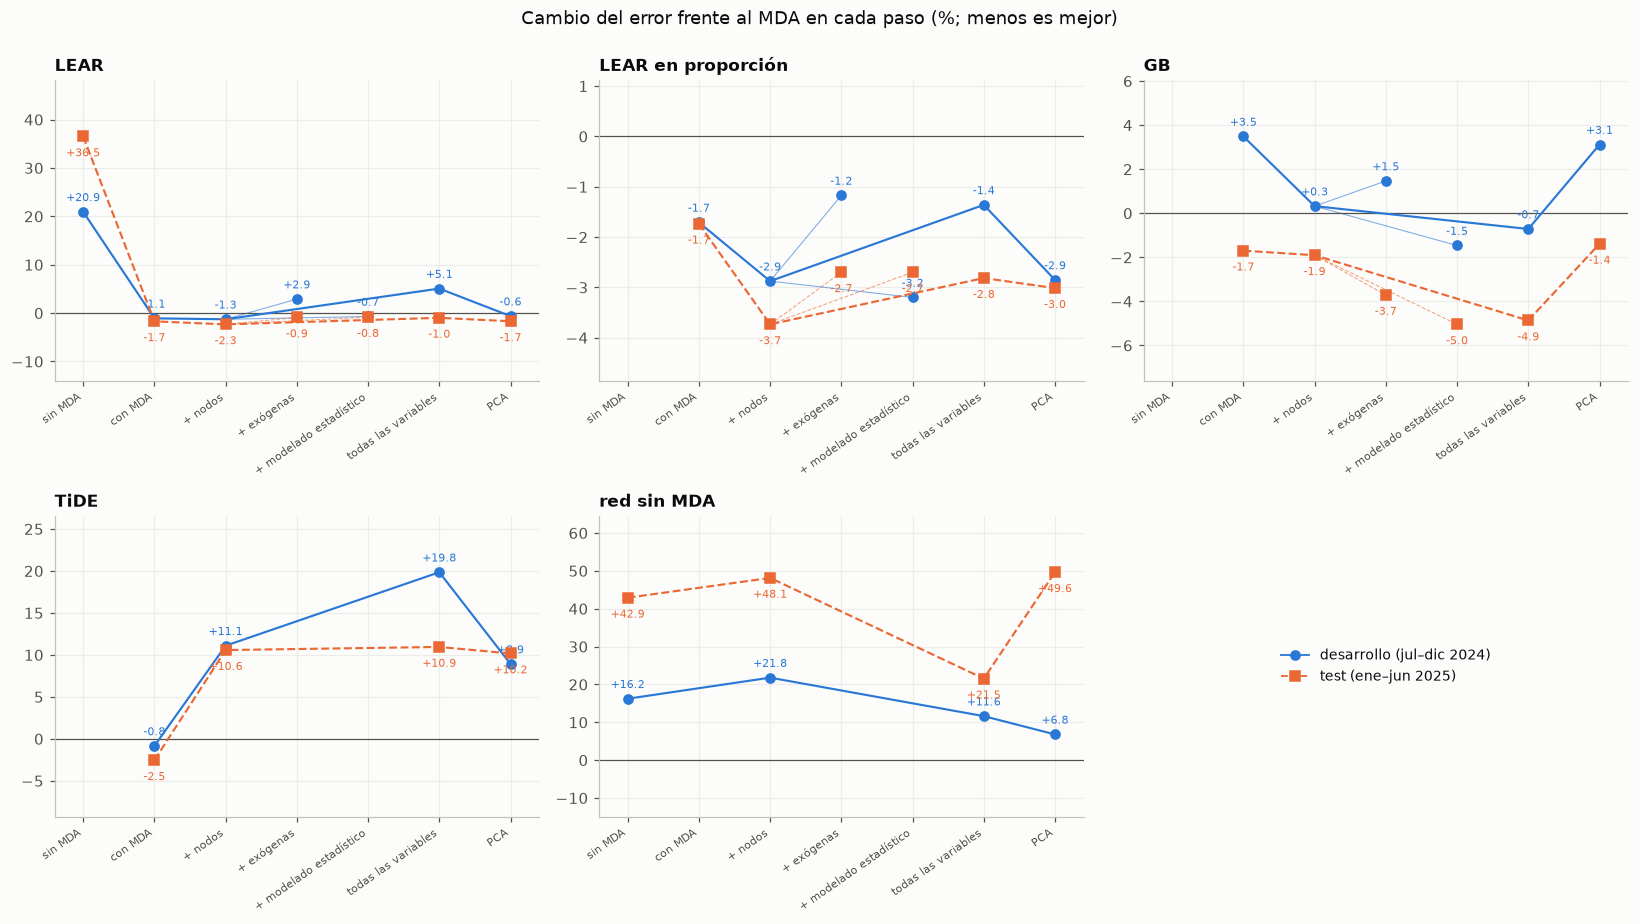

MAE desarrollo  \
modelo             paso                                     
LEAR               sin MDA                          268.0   
                   con MDA                          219.2   
                   + nodos                          218.8   
                   + exógenas                       228.0   
                   + modelado estadístico           220.1   
                   todas las variables              232.9   
                   PCA                              220.2   
LEAR en proporción con MDA                          217.8   
                   + nodos                          215.2   
                   + exógenas                       219.0   
                   + modelado estadístico           214.5   
                   todas las variables              218.6   
                   PCA                              215.3   
GB                 con MDA                          229.4   
                   + nodos                          222.3   
                   + exógenas                       224.9   
                   + modelado estadístico           218.4   
                   todas las variables              220.0   
                   PCA                              228.5   
TiDE               con MDA                          219.7   
                   + nodos                          246.2   
                   todas las variables              265.6   
                   PCA                              241.4   
red sin MDA        sin MDA                          257.6   
                   + nodos                          269.9   
                   todas las variables              247.4   
                   PCA                              236.7   

                                           vs MDA desarrollo (%)  \
modelo             paso                                            
LEAR               sin MDA                                  20.9   
                   con MDA                                  -1.1   
                   + nodos                                  -1.3   
                   + exógenas                                2.9   
                   + modelado estadístico                   -0.7   
                   todas las variables                       5.1   
                   PCA                                      -0.6   
LEAR en proporción con MDA                                  -1.7   
                   + nodos                                  -2.9   
                   + exógenas                               -1.2   
                   + modelado estadístico                   -3.2   
                   todas las variables                      -1.4   
                   PCA                                      -2.9   
GB                 con MDA                                   3.5   
                   + nodos                                   0.3   
                   + exógenas                                1.5   
                   + modelado estadístico                   -1.5   
                   todas las variables                      -0.7   
                   PCA                                       3.1   
TiDE               con MDA                                  -0.8   
                   + nodos                                  11.1   
                   todas las variables                      19.8   
                   PCA                                       8.9   
red sin MDA        sin MDA                                  16.2   
                   + nodos                                  21.8   
                   todas las variables                      11.6   
                   PCA                                       6.8   

                                           peor mes, desarrollo (%)  MAE test  \
modelo             paso                                                         
LEAR               sin MDA                                     71.0     250.4   
                   con MDA                               

In [2]:
# La escalera: cada modelo en cada paso, contra el MDA. Se decide en desarrollo; el test se muestra solo para ver si lo decidido se sostiene
TRAY = escalera.trayectoria(PASOS, Y, X, DEV, idx_extra=TEST)
escalera.figura(TRAY, ps, con_test=True, archivo=FIG / '08_escalera.png'); plt.show()
T = TRAY.rename(columns={'MAE_desarrollo': 'MAE desarrollo', 'cambio_desarrollo': 'vs MDA desarrollo (%)', 'peor_mes_desarrollo': 'peor mes, desarrollo (%)',
                         'MAE_test': 'MAE test', 'cambio_test': 'vs MDA test (%)', 'peor_mes_test': 'peor mes, test (%)'})
display(T.round(1).set_index(['modelo', 'paso'])); T.round(2).to_csv(REP / '08_escalera.csv', index=False)

Se observa lo siguiente (cambio del error contra el MDA, en desarrollo y, entre paréntesis, en el test):

- **El MDA es lo primero.** Sin él, LEAR queda 20.9% peor que el MDA (36.5% en el test) y la red sin MDA 16.2% (42.9%). Corregir al MDA deja a todos cerca de su nivel.
- **+ nodos** ayuda a quien le faltaban ejemplos: al GB (de +3.5% a +0.3%) y a LEAR en proporción (de −1.7% a −2.9%; −3.7% en el test). A LEAR casi no le cambia, y a TiDE y a la red sin MDA los empeora mucho (+11.1% y +21.8%).
- **+ exógenas** empeora a todos frente a "+ nodos" en desarrollo (LEAR de −1.3% a +2.9%, LEAR en proporción de −2.9% a −1.2%, GB de +0.3% a +1.5%). En el test, en cambio, al GB le va mejor con ellas (−3.7% contra −1.9%): desarrollo y test no coinciden.
- **+ modelado estadístico** es la rama que mejor funciona: el GB pasa a −1.5% (−5.0% en el test) y LEAR en proporción a −3.2% (−2.7%).
- **Todas las variables** no suma lo bueno de cada rama: LEAR empeora a +5.1%, LEAR en proporción y el GB quedan peor que con solo el modelado estadístico, y TiDE llega a +19.8%. A la red sin MDA sí la mejora (de +21.8% a +11.6%).
- **PCA** arregla a LEAR (de +5.1% a −0.6%) y a TiDE en parte (de +19.8% a +8.9%), deja igual a LEAR en proporción y empeora al GB (+3.1%). A la red sin MDA la mejora en desarrollo (+6.8%) pero se desbarata en el test (+49.6%).

Las decisiones grandes se sostienen en los dos periodos: corregir al MDA para todos, más nodos para el GB y LEAR en proporción, y el modelado estadístico para el GB. Las demás dependen del modelo, y varias cambian de signo entre desarrollo y test (las exógenas en el GB, el PCA en la red sin MDA). Lo que funciona es modelar bien el MTR y el MDA; agregar mucha información externa o resumirla no generaliza igual en todos los modelos.

**Por qué cada modelo responde distinto.** El comportamiento se explica en buena parte por la forma en que funciona cada uno:

- **LEAR** es lineal y se ajusta con una penalización (un LASSO por hora) que apaga variables. Con pocos parámetros efectivos, el MDA y sus rezagos le bastan: más nodos casi no lo cambian y las exógenas le agregan ruido de estimación. Con las 744 columnas la penalización no alcanza a apagar lo que sobra y, al ser lineal, extrapola cuando una variable toma un valor fuera de lo normal: un solo día (12 de septiembre de 2024) explica gran parte de su empeoramiento (6.4% con ese día y 1.8% sin él, notebook 07). El PCA lo corrige porque reduce las columnas que dicen lo mismo.
- **LEAR en proporción** pronostica la razón MTR/MDA, de modo que los días caros pesan igual que los baratos (notebook 05). Esto lo hace menos sensible a los extremos y es coherente con que lo que gana con nodos y con modelado estadístico se mantenga en el test.
- **El GB** está formado por árboles: no extrapola y puede elegir entre muchas variables, pero con ~300 días de Monclova memoriza ruido (3.5% peor que el MDA). Los 64 nodos le dan muchas más filas y variedad, lo que explica su mejora, y puede aprovechar el modelado estadístico (estadísticas móviles, red y días parecidos son las familias que más pierde, notebook 07). El PCA, en cambio, mezcla en componentes lo que el GB usa por separado y le quita detalle.
- **TiDE y la red sin MDA** son redes con muchos parámetros, que con ~300 días tienden a memorizar ruido (notebook 05). Más nodos o más variables significan más entradas y ejemplos de otros nodos que pueden arrastrarlas hacia patrones distintos a los de Monclova (una explicación posible, no comprobada), y por eso empeoran.
- **La red sin MDA** no ve el MDA, que concentra casi toda la información, y depende solo de la historia del MTR. Sus componentes de PCA se ajustan con datos hasta junio de 2024 y es probable que describan relaciones de esa época: en desarrollo se va deteriorando mes a mes (de −1% en julio a +74% en diciembre) y en el test se desbarata (+49.6%).

In [3]:
# La mejor versión de cada modelo: la de menor peor mes en desarrollo (si una más sencilla queda a menos de 0.5 puntos, la más sencilla). Son las piezas del notebook 10
MEJOR = escalera.mejor_version(PASOS, TRAY)
display(pd.DataFrame({k: {'mejor versión': p, 'MAE desarrollo': round(R.mae(P), 1), 'peor mes (%)': round(peor_mes(Y, X, P, DEV), 1)} for k, (p, P) in MEJOR.items()}).T)

,mejor versión,MAE desarrollo,peor mes (%)
LEAR,con MDA,219.2,0.2
LEAR en proporción,+ nodos,215.2,-0.8
GB,+ modelado estadístico,218.4,1.8
TiDE,con MDA,219.7,0.9
red sin MDA,PCA,236.7,74.3


Cada modelo sigue con su mejor versión: la de menor peor mes en desarrollo, es decir, la que pierde menos contra el MDA en su peor mes (notebook 04). Si una versión más sencilla queda a menos de 0.5 puntos, se prefiere la más sencilla, porque esa diferencia no se distingue del ruido:

- LEAR sin nodos (219.2; peor mes +0.2%);
- LEAR en proporción con 64 nodos (215.2; −0.8%), el único que le gana al MDA incluso en su peor mes;
- el GB con 64 nodos y modelado estadístico (218.4; +1.8%);
- TiDE sin nodos (219.7; +0.9%);
- la red sin MDA con PCA (236.7; +74.3%), su mejor versión aunque su peor mes la delata como inestable.

Son las mismas versiones que se obtenían con el error medio, y son las piezas que se combinan en el notebook 10.